<a href="https://colab.research.google.com/github/haniyathul/TESIS-HANIY/blob/main/Pemodelan_Data_Empiris_KKP_572_573.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
import zipfile

daftar_zip = [
    "/content/HASIL_PEMBAGIAN_CV.zip",
    "/content/HASIL_LENGKAP_ESF_TUNA.zip"
]

for path in daftar_zip:
    print("\nFILE:", os.path.basename(path))

    if os.path.exists(path):
        with zipfile.ZipFile(path, "r") as z:
            isi = z.namelist()
            print("✅ ZIP ditemukan")
            print("Jumlah file:", len(isi))
            print("Contoh isi:")
            for nama in isi[:10]:
                print(" -", nama)
    else:
        print("❌ ZIP belum ditemukan")



FILE: HASIL_PEMBAGIAN_CV.zip
✅ ZIP ditemukan
Jumlah file: 5
Contoh isi:
 - REKAP_UKURAN_FOLD.csv
 - METADATA_CV.json
 - INDEKS_TRAIN_VALIDASI.csv
 - IDENTITAS_FOLD_401_DATA.csv
 - PETA_RANDOM_DAN_SPATIAL_CV.png

FILE: HASIL_LENGKAP_ESF_TUNA.zip
✅ ZIP ditemukan
Jumlah file: 133
Contoh isi:
 - 01_PETA/GRID_LENGKAP_WPP_572_573.csv
 - 01_PETA/HEATMAP_KORELASI_XY.png
 - 01_PETA/PETA_10_VARIABEL_OSEANOGRAFI.png
 - 01_PETA/PETA_CPUE_GRID_INDONESIA.png
 - 01_PETA/PETA_GRID_LENGKAP_WPP_572_573.png
 - 02_EDA/BOXPLOT_CPUE_DAN_X.png
 - 02_EDA/HISTOGRAM_CPUE_DAN_X.png
 - 02_EDA/KORELASI_PEARSON_SPEARMAN.png
 - 02_EDA/KORELASI_X_TERHADAP_CPUE.png
 - 02_EDA/TABEL_KORELASI_XY.csv


In [2]:

# ==========================================================
# PEMULIHAN DATA PENELITIAN DARI 2 FILE ZIP
#
# 1. HASIL_LENGKAP_ESF_TUNA.zip
# 2. HASIL_PEMBAGIAN_CV.zip
#
# OUTPUT:
# - DATASET_MODEL : 13 dataset
# - CV_SPLITS     : Random 10-Fold + Spatial 4-Fold
#
# Tidak mengulang EDA, W, eigenvector, atau seleksi.
# ==========================================================

import zipfile
import numpy as np
import pandas as pd
from pathlib import Path
from io import BytesIO

# ----------------------------------------------------------
# 1. LOKASI ZIP
# ----------------------------------------------------------

ZIP_DATA = Path(
    "/content/HASIL_LENGKAP_ESF_TUNA.zip"
)

ZIP_CV = Path(
    "/content/HASIL_PEMBAGIAN_CV.zip"
)

for path in [ZIP_DATA, ZIP_CV]:
    if not path.exists():
        raise FileNotFoundError(
            f"Belum ditemukan: {path.name}. "
            "Tunggu upload selesai terlebih dahulu."
        )

# ----------------------------------------------------------
# 2. DAFTAR 13 DATASET
# ----------------------------------------------------------

KODE_DATASET = [
    "BASELINE",
    "MORAN_KNN5",
    "MORAN_DISTANCE",
    "MORAN_IDW",
    "LASSO_KNN5",
    "LASSO_DISTANCE",
    "LASSO_IDW",
    "STEPWISE_KNN5",
    "STEPWISE_DISTANCE",
    "STEPWISE_IDW",
    "SHAP_KNN5",
    "SHAP_DISTANCE",
    "SHAP_IDW"
]

DATASET_MODEL = {}

with zipfile.ZipFile(ZIP_DATA, "r") as z:

    semua_file = z.namelist()

    for kode in KODE_DATASET:

        nama_dicari = f"{kode}.csv"

        # Cari file di folder mana pun dalam ZIP
        kandidat = [
            f for f in semua_file
            if Path(f).name == nama_dicari
            and "09_DATASET_13_MODEL" in f
        ]

        if not kandidat:
            # Cadangan jika struktur folder berbeda
            kandidat = [
                f for f in semua_file
                if Path(f).name == nama_dicari
            ]

        if not kandidat:
            raise FileNotFoundError(
                f"{nama_dicari} tidak ditemukan "
                "dalam ZIP hasil penelitian."
            )

        with z.open(kandidat[0]) as f:
            DATASET_MODEL[kode] = pd.read_csv(f)

print("✅ Berhasil memuat", len(DATASET_MODEL), "dataset")

# ----------------------------------------------------------
# 3. CEK KESEJAJARAN DATASET
# ----------------------------------------------------------

BASE = DATASET_MODEL["BASELINE"]
N = len(BASE)

for kode, data in DATASET_MODEL.items():

    if len(data) != N:
        raise ValueError(
            f"Jumlah baris berbeda: {kode}"
        )

    pd.testing.assert_frame_equal(
        data[["Longitude", "Latitude", "cpue"]],
        BASE[["Longitude", "Latitude", "cpue"]]
    )

print("✅ Semua dataset memiliki", N, "observasi")

# ----------------------------------------------------------
# 4. BACA INDEKS CV ASLI DARI ZIP
# ----------------------------------------------------------

with zipfile.ZipFile(ZIP_CV, "r") as z:

    kandidat = [
        f for f in z.namelist()
        if Path(f).name == "INDEKS_TRAIN_VALIDASI.csv"
    ]

    if not kandidat:
        raise FileNotFoundError(
            "INDEKS_TRAIN_VALIDASI.csv "
            "tidak ditemukan dalam ZIP CV."
        )

    with z.open(kandidat[0]) as f:
        rincian_cv = pd.read_csv(f)

# ----------------------------------------------------------
# 5. REKONSTRUKSI SPLIT
# ----------------------------------------------------------

CV_SPLITS = {}

KONFIG_CV = {
    "RANDOM_10FOLD": 10,
    "SPATIAL_4FOLD": 4
}

for jenis_cv, jumlah_fold in KONFIG_CV.items():

    bagian_cv = rincian_cv[
        rincian_cv["Jenis CV"] == jenis_cv
    ]

    daftar_split = []

    for fold in range(1, jumlah_fold + 1):

        bagian_fold = bagian_cv[
            bagian_cv["Fold"] == fold
        ]

        # ID_Observasi pada file sebelumnya
        # berbasis 1, sedangkan iloc berbasis 0.
        idx_train = (
            bagian_fold[
                bagian_fold["Peran"] == "TRAIN"
            ]["ID_Observasi"]
            .to_numpy(dtype=int) - 1
        )

        idx_valid = (
            bagian_fold[
                bagian_fold["Peran"] == "VALIDASI"
            ]["ID_Observasi"]
            .to_numpy(dtype=int) - 1
        )

        # Validasi indeks
        assert len(idx_train) > 0
        assert len(idx_valid) > 0

        assert set(idx_train).isdisjoint(
            set(idx_valid)
        )

        assert len(
            np.union1d(idx_train, idx_valid)
        ) == N

        daftar_split.append(
            (idx_train, idx_valid)
        )

    CV_SPLITS[jenis_cv] = daftar_split

# ----------------------------------------------------------
# 6. VALIDASI SEMUA OBSERVASI MUNCUL SEKALI
# ----------------------------------------------------------

for jenis_cv, daftar_split in CV_SPLITS.items():

    seluruh_validasi = np.concatenate([
        idx_valid
        for _, idx_valid in daftar_split
    ])

    assert len(seluruh_validasi) == N

    assert np.array_equal(
        np.sort(seluruh_validasi),
        np.arange(N)
    )

# ----------------------------------------------------------
# 7. TAMPILKAN REKAP
# ----------------------------------------------------------

print("\n" + "=" * 60)
print("PEMULIHAN DATA DAN CV BERHASIL")
print("=" * 60)

print("Jumlah dataset        :", len(DATASET_MODEL))
print("Jumlah observasi      :", N)
print(
    "Random CV             :",
    len(CV_SPLITS["RANDOM_10FOLD"]),
    "fold"
)
print(
    "Spatial CV            :",
    len(CV_SPLITS["SPATIAL_4FOLD"]),
    "fold"
)

print("\n✅ DATASET_MODEL tersedia")
print("✅ CV_SPLITS tersedia")
print("✅ Fold asli berhasil dipulihkan")
print("✅ Siap menjalankan baseline 5 trial")


✅ Berhasil memuat 13 dataset
✅ Semua dataset memiliki 401 observasi

PEMULIHAN DATA DAN CV BERHASIL
Jumlah dataset        : 13
Jumlah observasi      : 401
Random CV             : 10 fold
Spatial CV            : 4 fold

✅ DATASET_MODEL tersedia
✅ CV_SPLITS tersedia
✅ Fold asli berhasil dipulihkan
✅ Siap menjalankan baseline 5 trial


Mounted at /content/drive
BASELINE GW-XGBOOST TWEEDIE
Observasi    : 401
Prediktor    : 10
Trial Optuna : 5
Inner CV     : 3
Random CV    : 10 Fold
Spatial CV   : 4 Fold
Output Drive : /content/drive/MyDrive/HASIL_BASELINE_GWXGBOOST_5TRIAL

MULAI: RANDOM_10FOLD

RANDOM_10FOLD | Fold 1/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 2/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 3/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 4/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 5/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 6/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 7/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 8/10
✅ Fold sudah selesai, dilewati.

RANDOM_10FOLD | Fold 9/10
Train: 361 | Validasi: 40
    Trial 4 | RMSE inner = 13.79915
    Trial 5 | RMSE inner = 13.39922
RMSE inner terbaik: 13.39922
✅ Fold selesai | RMSE=14.6236 | MAE=7.8658 | R2=0.5024

RANDOM_10FOLD | Fold 10/10
Train: 361 | Validasi: 40
   

,Model,Jenis_CV,Fold,N_Train,N_Validasi,Trials,RMSE_Inner,RMSE,MAE,R2,Bandwidth_k
0,GW-XGBoost Tweedie,RANDOM_10FOLD,1,360,41,5,13.39079,13.79119,8.39075,0.44406,100
1,GW-XGBoost Tweedie,RANDOM_10FOLD,2,361,40,5,13.31654,10.65221,5.69300,0.31371,30
2,GW-XGBoost Tweedie,RANDOM_10FOLD,3,361,40,5,13.43198,8.15498,4.69606,0.66446,100
3,GW-XGBoost Tweedie,RANDOM_10FOLD,4,361,40,5,13.37522,10.61297,5.74375,0.53616,30
4,GW-XGBoost Tweedie,RANDOM_10FOLD,5,361,40,5,13.29152,8.30389,4.91611,0.19840,30
5,GW-XGBoost Tweedie,RANDOM_10FOLD,6,361,40,5,13.79066,10.18030,5.10241,0.31820,100
6,GW-XGBoost Tweedie,RANDOM_10FOLD,7,361,40,5,12.69742,15.76019,7.03128,0.36587,100
7,GW-XGBoost Tweedie,RANDOM_10FOLD,8,361,40,5,11.82867,23.40693,12.54776,0.34771,30
8,GW-XGBoost Tweedie,RANDOM_10FOLD,9,361,40,5,13.39922,14.62356,7.86578,0.50244,30
9,GW-XGBoost Tweedie,RANDOM_10FOLD,10,361,40,5,13.59287,9.32568,5.11853,0.63679,30



PERBANDINGAN BASELINE RANDOM VS SPATIAL


,Model,Metode_CV,Jumlah_Fold,N_Observasi,RMSE,MAE,R2
0,GW-XGBoost Tweedie,RANDOM_10FOLD,10,401,13.239546,6.714733,0.452309
1,GW-XGBoost Tweedie,SPATIAL_4FOLD,4,401,19.295095,9.720011,-0.163276


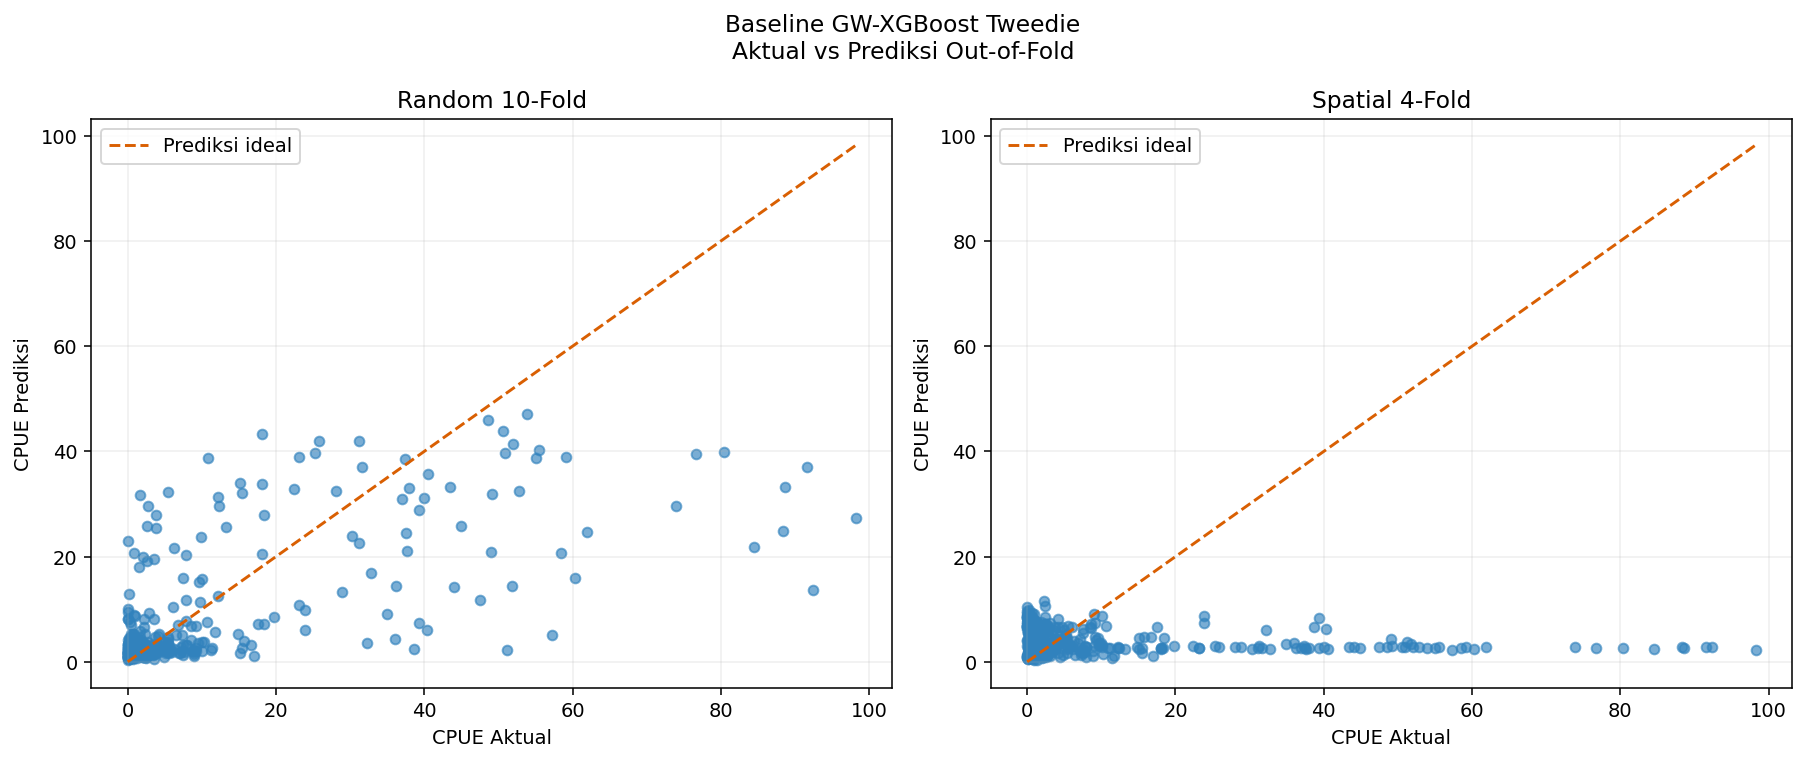

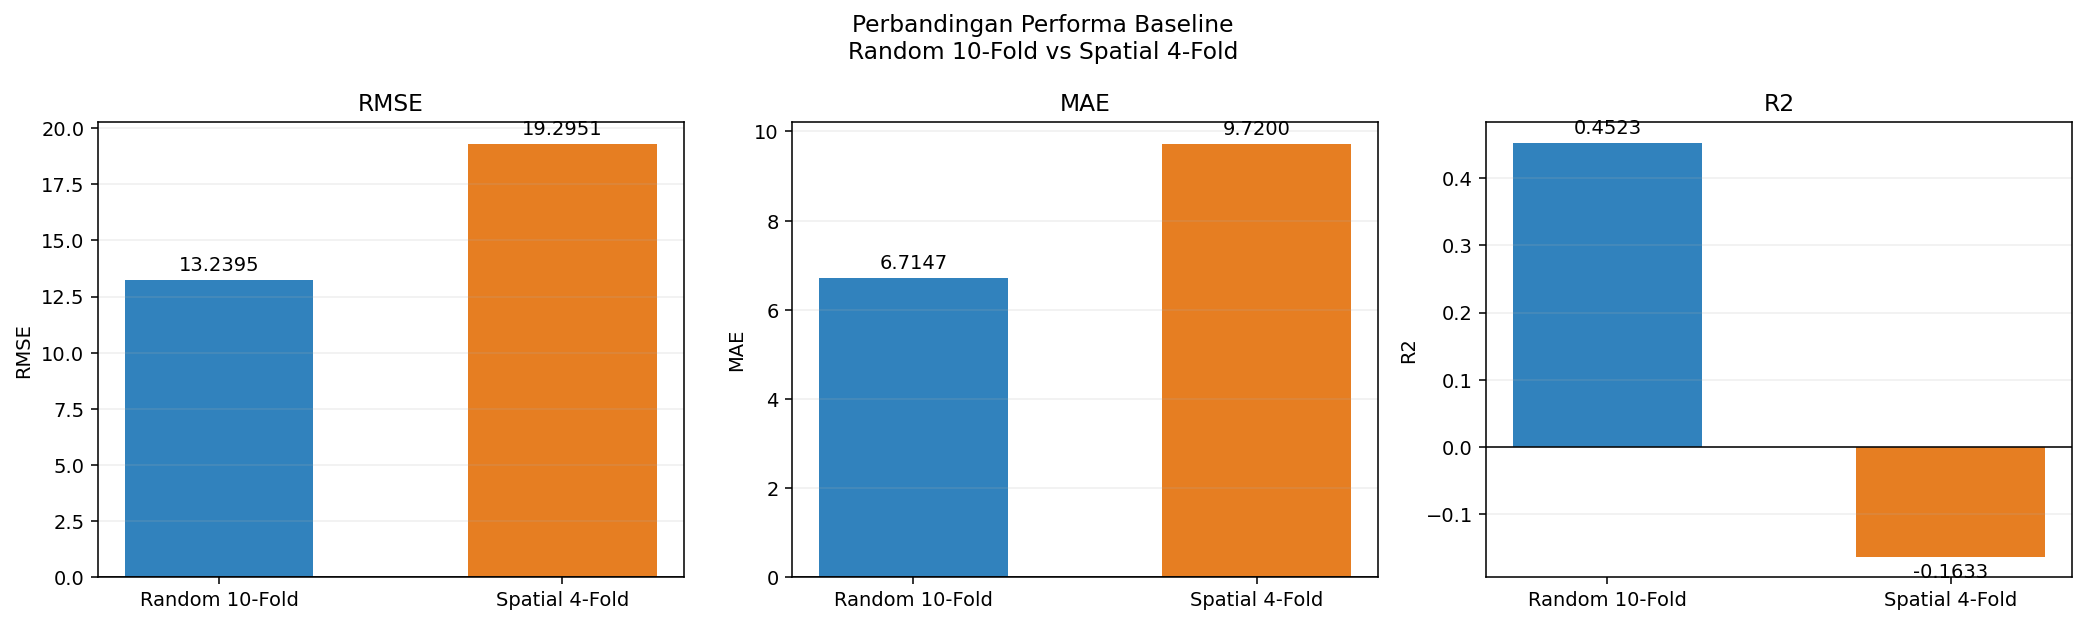

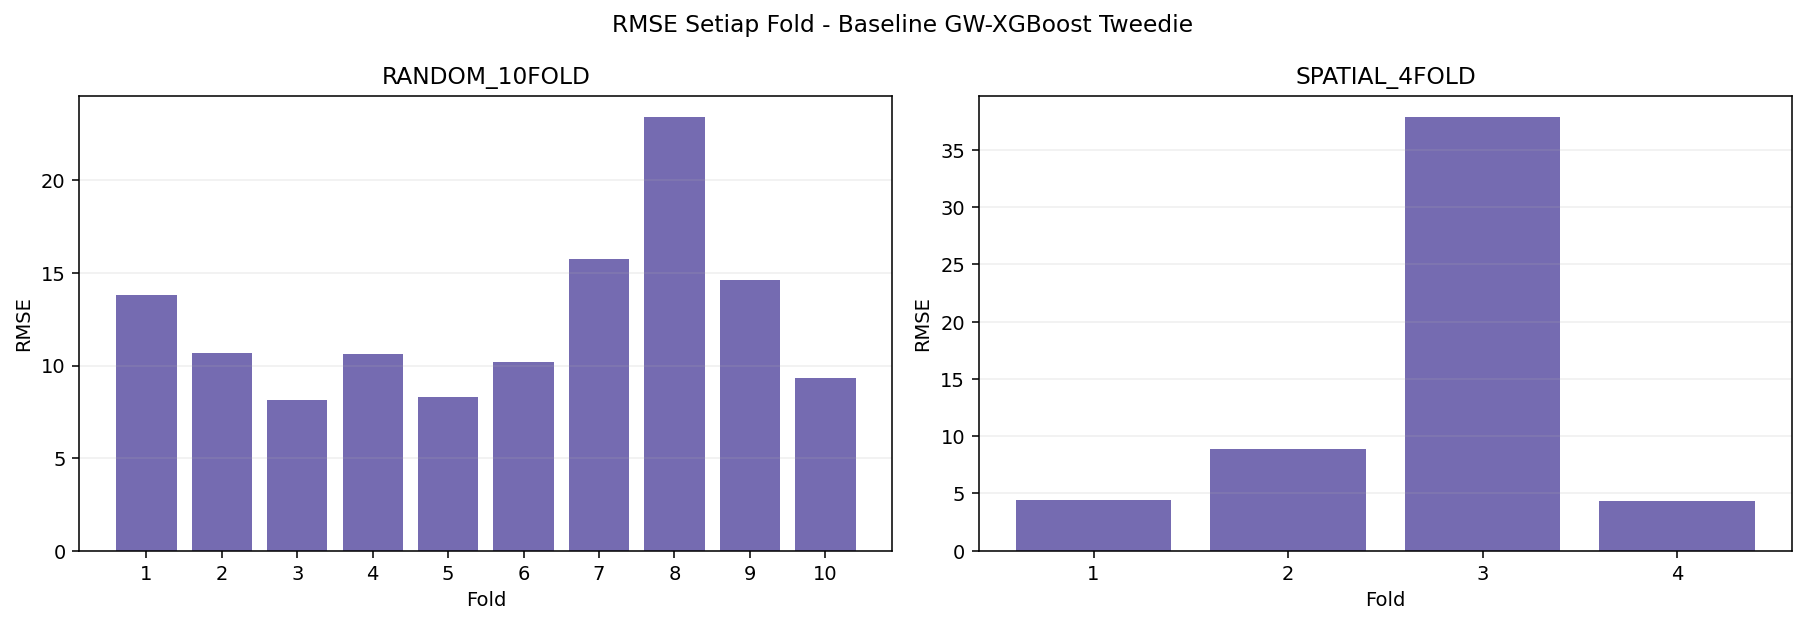

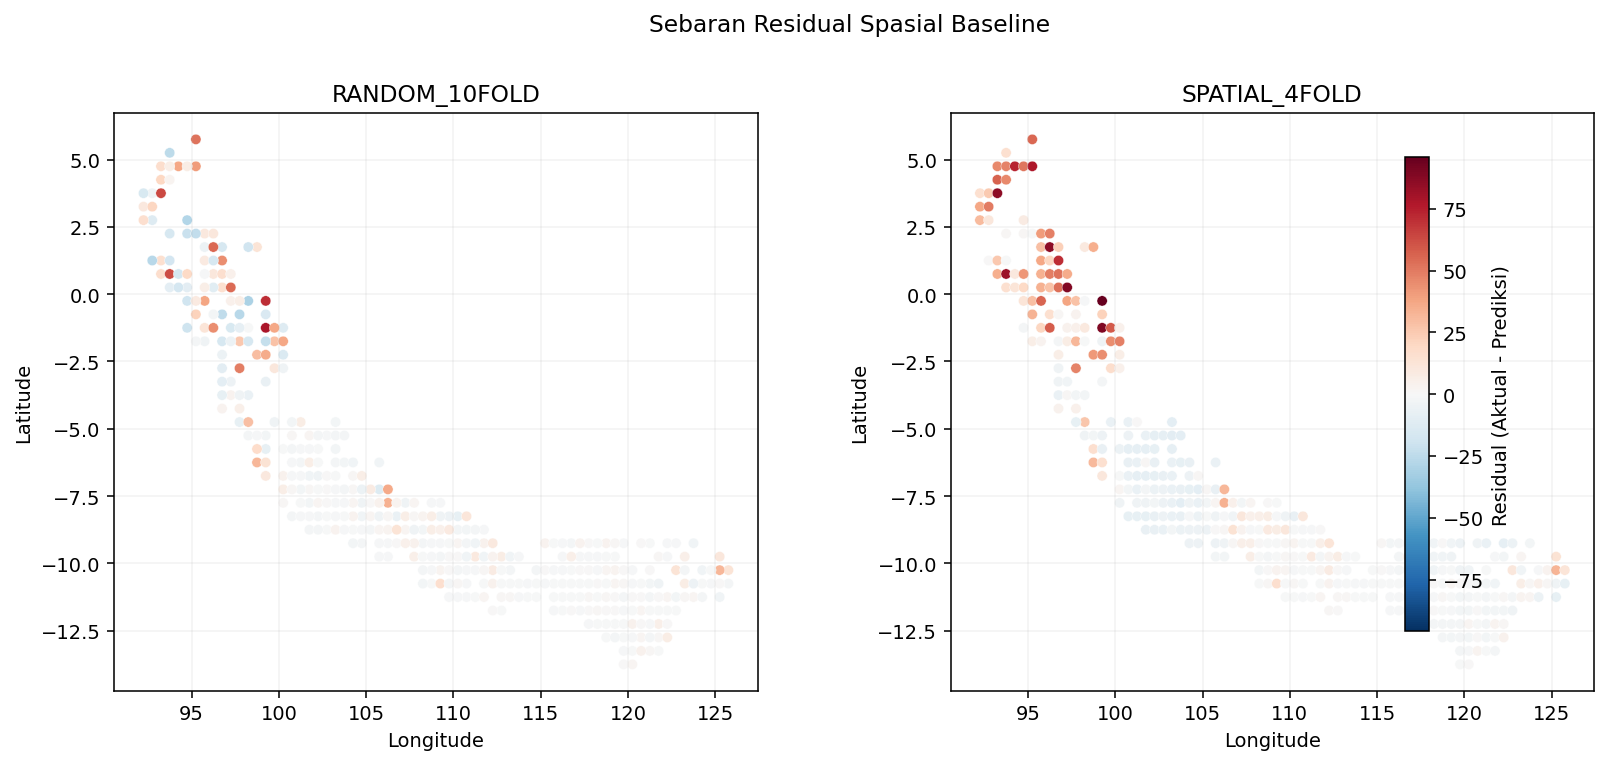


BASELINE GW-XGBOOST TWEEDIE SELESAI
✅ Random 10-Fold lengkap
✅ Spatial 4-Fold lengkap
✅ Optuna 5 trial per outer fold
✅ 3 inner fold untuk tuning
✅ Prediksi OOF seluruh 401 lokasi
✅ RMSE, MAE, R2 dihitung
✅ Parameter dan progres tersimpan di Drive
✅ Grafik dan CSV tersimpan
✅ ZIP sudah dibuat

FOLDER GOOGLE DRIVE:
/content/drive/MyDrive/HASIL_BASELINE_GWXGBOOST_5TRIAL

ZIP GOOGLE DRIVE:
/content/drive/MyDrive/HASIL_BASELINE_GWXGBOOST_5TRIAL.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ================================================================
# BASELINE GW-XGBOOST TWEEDIE - 5 TRIAL OPTUNA
# ================================================================
#
# DATA:
#   401 observasi
#   10 prediktor oseanografi
#   Tanpa eigenvector / tanpa ESF
#
# CROSS-VALIDATION OUTER:
#   RANDOM 10-FOLD
#   SPATIAL CLUSTER 4-FOLD
#
# TUNING:
#   Optuna TPE
#   5 trial per outer fold
#   3 inner fold
#   11 hyperparameter
#   Seluruh titik validasi inner digunakan
#
# GEOGRAPHIC WEIGHTING:
#   Haversine distance (km)
#   Adaptive Gaussian kernel
#   Satu model XGBoost lokal per titik target
#
# PENYIMPANAN:
#   Google Drive
#   Checkpoint setiap fold
#   Backup studi Optuna setiap trial
#
# OUTPUT:
#   RMSE, MAE, R2
#   Prediksi OOF
#   Parameter terbaik per fold
#   Grafik perbandingan
#   Residual spasial
#   ZIP seluruh hasil
#
# INPUT:
#   DATASET_MODEL
#   CV_SPLITS
# ================================================================

!pip -q install optuna xgboost

import os
import json
import shutil
import sqlite3
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from pathlib import Path
from google.colab import drive, files
from IPython.display import display

from sklearn.model_selection import KFold, GroupKFold
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import haversine_distances
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ================================================================
# 1. HUBUNGKAN GOOGLE DRIVE
# ================================================================

drive.mount("/content/drive")

# Semua hasil disimpan di Google Drive.
FOLDER_DRIVE = Path(
    "/content/drive/MyDrive/"
    "HASIL_BASELINE_GWXGBOOST_5TRIAL"
)

FOLDER_DRIVE.mkdir(
    parents=True,
    exist_ok=True
)

# Database aktif Optuna disimpan di disk lokal
# demi menghindari masalah SQLite pada Google Drive.
# Setiap trial selesai, database dibackup ke Drive.

FOLDER_DB_LOKAL = Path(
    "/content/OPTUNA_BASELINE_5TRIAL_DB"
)

FOLDER_DB_LOKAL.mkdir(
    parents=True,
    exist_ok=True
)

# ================================================================
# 2. PENGATURAN EKSPERIMEN
# ================================================================

SEED = 2026
R_BUMI_KM = 6371.0088

N_TRIALS = 5
N_INNER = 3
N_STARTUP_TRIALS = 3

DAFTAR_CV = [
    "RANDOM_10FOLD",
    "SPATIAL_4FOLD"
]

VAR_X = [
    "so",
    "thetao",
    "zos",
    "uo",
    "vo",
    "chl",
    "o2",
    "mlotst",
    "nppv",
    "Kecepatan"
]

PARAMETER_K = [
    30, 45, 60, 80, 100, 120
]

# ================================================================
# 3. AMBIL DATA DAN SPLIT YANG SUDAH DIPULIHKAN
# ================================================================

if "DATASET_MODEL" not in globals():
    raise NameError(
        "DATASET_MODEL belum ada. "
        "Jalankan cell pemulihan ZIP dahulu."
    )

if "CV_SPLITS" not in globals():
    raise NameError(
        "CV_SPLITS belum ada. "
        "Jalankan cell pemulihan ZIP dahulu."
    )

DATA = DATASET_MODEL["BASELINE"].copy()

N = len(DATA)

KOLOM_WAJIB = (
    VAR_X + ["cpue", "Latitude", "Longitude"]
)

for kolom in KOLOM_WAJIB:
    if kolom not in DATA.columns:
        raise ValueError(
            f"Kolom {kolom} tidak ditemukan."
        )

X_ALL = DATA[VAR_X].to_numpy(dtype=float)

Y_ALL = DATA["cpue"].to_numpy(dtype=float)

COORD_ALL = DATA[
    ["Latitude", "Longitude"]
].to_numpy(dtype=float)

if not np.isfinite(X_ALL).all():
    raise ValueError("Ada X yang tidak valid.")

if not np.isfinite(Y_ALL).all():
    raise ValueError("Ada CPUE yang tidak valid.")

if not np.isfinite(COORD_ALL).all():
    raise ValueError("Ada koordinat tidak valid.")

if np.any(Y_ALL < 0):
    raise ValueError(
        "CPUE harus nonnegatif untuk Tweedie."
    )

if len(CV_SPLITS["RANDOM_10FOLD"]) != 10:
    raise ValueError("Random CV bukan 10 fold.")

if len(CV_SPLITS["SPATIAL_4FOLD"]) != 4:
    raise ValueError("Spatial CV bukan 4 fold.")

# Validasi pembagian asli
for jenis_cv in DAFTAR_CV:

    seluruh_validasi = []

    for idx_train, idx_valid in CV_SPLITS[jenis_cv]:

        idx_train = np.asarray(idx_train, dtype=int)
        idx_valid = np.asarray(idx_valid, dtype=int)

        if len(np.intersect1d(
            idx_train, idx_valid
        )) > 0:
            raise ValueError(
                f"Train-validasi overlap: {jenis_cv}"
            )

        if len(np.union1d(
            idx_train, idx_valid
        )) != N:
            raise ValueError(
                f"Fold tidak lengkap: {jenis_cv}"
            )

        seluruh_validasi.extend(idx_valid.tolist())

    if not np.array_equal(
        np.sort(seluruh_validasi),
        np.arange(N)
    ):
        raise ValueError(
            f"OOF tidak mencakup semua lokasi: {jenis_cv}"
        )

# Identitas eksperimen untuk melindungi checkpoint
fingerprint = hashlib.sha256()

fingerprint.update(
    np.ascontiguousarray(
        DATA[KOLOM_WAJIB].to_numpy(dtype=np.float64)
    ).tobytes()
)

for jenis_cv in DAFTAR_CV:
    for it, iv in CV_SPLITS[jenis_cv]:
        fingerprint.update(
            np.asarray(it, dtype=np.int64).tobytes()
        )
        fingerprint.update(
            np.asarray(iv, dtype=np.int64).tobytes()
        )

fingerprint.update(
    f"ntrial={N_TRIALS};inner={N_INNER};"
    f"startup={N_STARTUP_TRIALS};seed={SEED}"
    .encode()
)

ID_EKSPERIMEN = fingerprint.hexdigest()[:20]

print("=" * 65)
print("BASELINE GW-XGBOOST TWEEDIE")
print("=" * 65)

print("Observasi    :", N)
print("Prediktor    :", len(VAR_X))
print("Trial Optuna :", N_TRIALS)
print("Inner CV     :", N_INNER)
print("Random CV    : 10 Fold")
print("Spatial CV   : 4 Fold")
print("Output Drive :", FOLDER_DRIVE)

# ================================================================
# 4. FUNGSI JARAK HAVERSINE
# ================================================================

def jarak_haversine(coord_target, coord_train):

    return haversine_distances(
        np.radians(coord_target),
        np.radians(coord_train)
    ) * R_BUMI_KM


# ================================================================
# 5. FUNGSI ADAPTIVE GAUSSIAN
# ================================================================

def bobot_adaptive_gaussian(jarak, k):

    d = np.asarray(jarak, dtype=float)

    if not (1 <= k <= len(d)):
        raise ValueError(
            "bandwidth_k melebihi jumlah train."
        )

    b = float(
        np.partition(d, k - 1)[k - 1]
    )

    b = max(b, 1e-6)

    w = np.exp(
        -0.5 * (d / b) ** 2
    )

    total = float(w.sum())

    if not np.isfinite(total) or total <= 0:
        raise ValueError(
            "Bobot geografis tidak valid."
        )

    w = w / w.mean()

    return w, b


# ================================================================
# 6. PREDIKSI GW-XGBOOST TWEEDIE LOKAL
# ================================================================

def prediksi_lokal(
    X_train,
    y_train,
    X_target,
    D_target_train,
    params
):

    parameter = params.copy()

    k = int(parameter.pop("bandwidth_k"))

    parameter.update({
        "objective": "reg:tweedie",
        "tree_method": "hist",
        "random_state": SEED,
        "n_jobs": 1,
        "verbosity": 0
    })

    prediksi = np.empty(len(X_target))
    bandwidth = np.empty(len(X_target))

    for i in range(len(X_target)):

        w, b = bobot_adaptive_gaussian(
            D_target_train[i], k
        )

        model = XGBRegressor(
            **parameter
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=w
        )

        prediksi[i] = float(
            model.predict(
                X_target[i:i+1]
            )[0]
        )

        bandwidth[i] = b

    return prediksi, bandwidth


# ================================================================
# 7. MEMBUAT INNER CV
# ================================================================

def buat_inner_splits(
    X_train,
    y_train,
    coord_train,
    jenis_cv
):

    if jenis_cv == "RANDOM_10FOLD":

        cv = KFold(
            n_splits=N_INNER,
            shuffle=True,
            random_state=SEED
        )

        raw_splits = list(
            cv.split(X_train)
        )

    else:

        # Spatial inner CV dibentuk hanya
        # dari data training outer.

        lon = coord_train[:, 1]
        lat = coord_train[:, 0]

        lat_ref = np.deg2rad(
            np.mean(lat)
        )

        XY_KM = np.column_stack([
            lon * 111.32 * np.cos(lat_ref),
            lat * 111.32
        ])

        groups = KMeans(
            n_clusters=N_INNER,
            n_init=20,
            random_state=SEED
        ).fit_predict(XY_KM)

        cv = GroupKFold(
            n_splits=N_INNER
        )

        raw_splits = list(
            cv.split(
                X_train,
                y_train,
                groups=groups
            )
        )

    hasil = []

    for it, iv in raw_splits:

        # Gunakan SEMUA lokasi validasi inner.
        # Tidak ada pengambilan sampel target.

        D = jarak_haversine(
            coord_train[iv],
            coord_train[it]
        )

        hasil.append({
            "train": it,
            "valid": iv,
            "jarak": D
        })

    return hasil


# ================================================================
# 8. SARAN 11 HYPERPARAMETER OPTUNA
# ================================================================

def sarankan_parameter(trial, pilihan_k):

    return {
        "n_estimators": trial.suggest_categorical(
            "n_estimators",
            [50, 75, 100, 125]
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 4
        ),

        "learning_rate": trial.suggest_categorical(
            "learning_rate",
            [0.01, 0.03, 0.05, 0.1]
        ),

        "subsample": trial.suggest_categorical(
            "subsample",
            [0.6, 0.7, 0.8, 0.9]
        ),

        "colsample_bytree": trial.suggest_categorical(
            "colsample_bytree",
            [0.6, 0.7, 0.8]
        ),

        "gamma": trial.suggest_categorical(
            "gamma",
            [0.1, 0.3, 0.5, 1.0]
        ),

        "reg_alpha": trial.suggest_categorical(
            "reg_alpha",
            [0.1, 0.3, 0.5, 1.0, 2.0]
        ),

        "reg_lambda": trial.suggest_categorical(
            "reg_lambda",
            [1.0, 2.0, 3.0, 5.0]
        ),

        "min_child_weight": trial.suggest_categorical(
            "min_child_weight",
            [5, 7, 10, 13]
        ),

        "tweedie_variance_power": trial.suggest_float(
            "tweedie_variance_power",
            1.1, 1.9,
            step=0.1
        ),

        "bandwidth_k": trial.suggest_categorical(
            "bandwidth_k",
            pilihan_k
        )
    }


# ================================================================
# 9. BACKUP DATABASE OPTUNA KE DRIVE
# ================================================================

def backup_database(db_lokal, db_drive):

    # SQLite backup API membuat salinan konsisten
    # tanpa menyalin file database yang sedang ditulis.

    with sqlite3.connect(str(db_lokal)) as src:
        with sqlite3.connect(str(db_drive)) as dst:
            src.backup(dst)


# ================================================================
# 10. TUNING OPTUNA SATU OUTER FOLD
# ================================================================

def tuning_optuna(
    X_train,
    y_train,
    coord_train,
    jenis_cv,
    fold_ke
):

    inner = buat_inner_splits(
        X_train,
        y_train,
        coord_train,
        jenis_cv
    )

    jumlah_min_train = min(
        len(b["train"]) for b in inner
    )

    pilihan_k = [
        k for k in PARAMETER_K
        if k <= jumlah_min_train
    ]

    if len(pilihan_k) == 0:
        raise ValueError(
            "Tidak ada bandwidth_k yang valid."
        )

    def objective(trial):

        params = sarankan_parameter(
            trial,
            pilihan_k
        )

        aktual_gabungan = []
        prediksi_gabungan = []

        for bagian in inner:

            it = bagian["train"]
            iv = bagian["valid"]

            pred, _ = prediksi_lokal(
                X_train[it],
                y_train[it],
                X_train[iv],
                bagian["jarak"],
                params
            )

            if not np.isfinite(pred).all():
                raise ValueError(
                    "Prediksi inner tidak valid."
                )

            aktual_gabungan.extend(
                y_train[iv].tolist()
            )

            prediksi_gabungan.extend(
                pred.tolist()
            )

        rmse = np.sqrt(
            mean_squared_error(
                aktual_gabungan,
                prediksi_gabungan
            )
        )

        return float(rmse)

    # Database aktif pada disk lokal
    nama_db = (
        f"OPTUNA_{jenis_cv}_FOLD{fold_ke}.db"
    )

    db_lokal = FOLDER_DB_LOKAL / nama_db
    db_drive = FOLDER_DRIVE / nama_db

    # Jika runtime baru, salin database dari Drive
    if db_drive.exists() and not db_lokal.exists():
        shutil.copy2(db_drive, db_lokal)

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED,
            n_startup_trials=N_STARTUP_TRIALS
        ),
        study_name=(
            f"BASELINE_5TRIAL_{jenis_cv}_FOLD{fold_ke}"
        ),
        storage=f"sqlite:///{db_lokal}",
        load_if_exists=True
    )

    jumlah_selesai = sum(
        t.state == optuna.trial.TrialState.COMPLETE
        for t in study.trials
    )

    sisa = max(
        0,
        N_TRIALS - jumlah_selesai
    )

    def callback(study, trial):

        if trial.state == optuna.trial.TrialState.COMPLETE:

            print(
                f"    Trial {trial.number + 1} | "
                f"RMSE inner = {trial.value:.5f}",
                flush=True
            )

        # Backup database setelah setiap trial
        backup_database(
            db_lokal,
            db_drive
        )

        # Simpan riwayat trial agar dapat diperiksa
        study.trials_dataframe().to_csv(
            FOLDER_DRIVE /
            f"RIWAYAT_{jenis_cv}_FOLD{fold_ke}.csv",
            index=False
        )

    if sisa > 0:

        study.optimize(
            objective,
            n_trials=sisa,
            callbacks=[callback],
            show_progress_bar=False,
            gc_after_trial=True
        )

    # Pastikan database terbaru sudah ada di Drive
    backup_database(db_lokal, db_drive)

    return study


# ================================================================
# 11. LOOP KEDUA METODE CV
# ================================================================

SEMUA_HASIL = []
SEMUA_PREDIKSI = []

for jenis_cv in DAFTAR_CV:

    daftar_fold = CV_SPLITS[jenis_cv]

    print("\n" + "=" * 65)
    print("MULAI:", jenis_cv)
    print("=" * 65)

    for fold_ke, (it, iv) in enumerate(
        daftar_fold,
        start=1
    ):

        print(
            f"\n{jenis_cv} | Fold "
            f"{fold_ke}/{len(daftar_fold)}",
            flush=True
        )

        path_hasil = FOLDER_DRIVE / (
            f"HASIL_{jenis_cv}_FOLD{fold_ke}.csv"
        )

        path_pred = FOLDER_DRIVE / (
            f"PREDIKSI_{jenis_cv}_FOLD{fold_ke}.csv"
        )

        path_param = FOLDER_DRIVE / (
            f"PARAMETER_{jenis_cv}_FOLD{fold_ke}.json"
        )

        # ------------------------------------------------
        # CEK CHECKPOINT FOLD SELESAI
        # ------------------------------------------------

        checkpoint_ok = False

        if (
            path_hasil.exists()
            and path_pred.exists()
            and path_param.exists()
        ):

            try:

                hasil_lama = pd.read_csv(path_hasil)
                pred_lama = pd.read_csv(path_pred)

                with open(path_param, "r") as f:
                    param_lama = json.load(f)

                checkpoint_ok = (
                    param_lama.get("ID_Eksperimen")
                    == ID_EKSPERIMEN
                    and param_lama.get("Trials") == N_TRIALS
                    and len(hasil_lama) == 1
                    and len(pred_lama) == len(iv)
                    and set(
                        pred_lama["ID_Observasi"]
                        .astype(int)
                    ) == set(np.asarray(iv) + 1)
                )

            except Exception:
                checkpoint_ok = False

        if checkpoint_ok:

            print("✅ Fold sudah selesai, dilewati.")

            SEMUA_HASIL.append(hasil_lama)
            SEMUA_PREDIKSI.append(pred_lama)

            continue

        # ------------------------------------------------
        # DATA TRAIN DAN VALIDASI OUTER
        # ------------------------------------------------

        X_train = X_ALL[it]
        y_train = Y_ALL[it]
        coord_train = COORD_ALL[it]

        X_valid = X_ALL[iv]
        y_valid = Y_ALL[iv]
        coord_valid = COORD_ALL[iv]

        print(
            "Train:", len(it),
            "| Validasi:", len(iv)
        )

        # ------------------------------------------------
        # OPTIMASI HYPERPARAMETER
        # ------------------------------------------------

        study = tuning_optuna(
            X_train,
            y_train,
            coord_train,
            jenis_cv,
            fold_ke
        )

        params_terbaik = study.best_params.copy()

        print(
            "RMSE inner terbaik:",
            round(study.best_value, 5)
        )

        # ------------------------------------------------
        # PREDIKSI OUTER FOLD
        # ------------------------------------------------

        D_outer = jarak_haversine(
            coord_valid,
            coord_train
        )

        y_pred, bandwidth_km = prediksi_lokal(
            X_train,
            y_train,
            X_valid,
            D_outer,
            params_terbaik
        )

        if not np.isfinite(y_pred).all():
            raise ValueError(
                f"Prediksi outer tidak valid: {jenis_cv}"
            )

        # ------------------------------------------------
        # METRIK EVALUASI
        # ------------------------------------------------

        rmse = float(
            np.sqrt(
                mean_squared_error(
                    y_valid,
                    y_pred
                )
            )
        )

        mae = float(
            mean_absolute_error(
                y_valid,
                y_pred
            )
        )

        r2 = float(
            r2_score(
                y_valid,
                y_pred
            )
        )

        hasil_fold = pd.DataFrame([{
            "Model": "GW-XGBoost Tweedie",
            "Jenis_CV": jenis_cv,
            "Fold": fold_ke,
            "N_Train": len(it),
            "N_Validasi": len(iv),
            "Trials": N_TRIALS,
            "RMSE_Inner": study.best_value,
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
            "Bandwidth_k": params_terbaik["bandwidth_k"]
        }])

        pred_fold = pd.DataFrame({
            "Jenis_CV": jenis_cv,
            "Fold": fold_ke,
            "ID_Observasi": np.asarray(iv) + 1,
            "Longitude": coord_valid[:, 1],
            "Latitude": coord_valid[:, 0],
            "CPUE_Aktual": y_valid,
            "CPUE_Prediksi": y_pred,
            "Residual": y_valid - y_pred,
            "Bandwidth_KM": bandwidth_km
        })

        # ------------------------------------------------
        # SIMPAN HASIL LANGSUNG KE GOOGLE DRIVE
        # ------------------------------------------------

        record_param = {
            "Model": "BASELINE",
            "Jenis_CV": jenis_cv,
            "Fold": fold_ke,
            "Trials": N_TRIALS,
            "ID_Eksperimen": ID_EKSPERIMEN,
            "RMSE_Inner": float(study.best_value),
            "Parameter_Terbaik": params_terbaik
        }

        # Parameter dan prediksi ditulis sebelum
        # file hasil fold sebagai penanda selesai.
        with open(path_param, "w") as f:
            json.dump(record_param, f, indent=2)

        pred_fold.to_csv(
            path_pred,
            index=False
        )

        hasil_fold.to_csv(
            path_hasil,
            index=False
        )

        SEMUA_HASIL.append(hasil_fold)
        SEMUA_PREDIKSI.append(pred_fold)

        print(
            f"✅ Fold selesai | "
            f"RMSE={rmse:.4f} | "
            f"MAE={mae:.4f} | "
            f"R2={r2:.4f}",
            flush=True
        )

# ================================================================
# 12. GABUNGKAN SEMUA HASIL
# ================================================================

HASIL_FOLD_BASELINE = pd.concat(
    SEMUA_HASIL,
    ignore_index=True
)

PREDIKSI_OOF_BASELINE = pd.concat(
    SEMUA_PREDIKSI,
    ignore_index=True
)

HASIL_FOLD_BASELINE.to_csv(
    FOLDER_DRIVE / "HASIL_14_FOLD_BASELINE.csv",
    index=False
)

PREDIKSI_OOF_BASELINE.to_csv(
    FOLDER_DRIVE / "PREDIKSI_OOF_BASELINE.csv",
    index=False
)

print("\nHASIL PER FOLD:")
display(HASIL_FOLD_BASELINE.round(5))

# ================================================================
# 13. HITUNG METRIK OOF RANDOM DAN SPATIAL
# ================================================================

rekap = []

for jenis_cv in DAFTAR_CV:

    bagian = PREDIKSI_OOF_BASELINE[
        PREDIKSI_OOF_BASELINE["Jenis_CV"] == jenis_cv
    ].sort_values("ID_Observasi")

    if len(bagian) != N:
        raise ValueError(
            f"{jenis_cv}: jumlah prediksi OOF tidak lengkap."
        )

    if not np.array_equal(
        bagian["ID_Observasi"].to_numpy(dtype=int),
        np.arange(1, N + 1)
    ):
        raise ValueError(
            f"{jenis_cv}: ID OOF tidak lengkap/duplikat."
        )

    y = bagian["CPUE_Aktual"].to_numpy()
    pred = bagian["CPUE_Prediksi"].to_numpy()

    rekap.append({
        "Model": "GW-XGBoost Tweedie",
        "Metode_CV": jenis_cv,
        "Jumlah_Fold": len(CV_SPLITS[jenis_cv]),
        "N_Observasi": N,
        "RMSE": float(
            np.sqrt(mean_squared_error(y, pred))
        ),
        "MAE": float(mean_absolute_error(y, pred)),
        "R2": float(r2_score(y, pred))
    })

PERBANDINGAN_BASELINE = pd.DataFrame(rekap)

print("\n" + "=" * 65)
print("PERBANDINGAN BASELINE RANDOM VS SPATIAL")
print("=" * 65)

display(PERBANDINGAN_BASELINE.round(6))

PERBANDINGAN_BASELINE.to_csv(
    FOLDER_DRIVE / "PERBANDINGAN_BASELINE.csv",
    index=False
)

# ================================================================
# 14. GRAFIK AKTUAL VS PREDIKSI
# ================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=140
)

for ax, jenis_cv in zip(axes, DAFTAR_CV):

    bagian = PREDIKSI_OOF_BASELINE[
        PREDIKSI_OOF_BASELINE["Jenis_CV"] == jenis_cv
    ]

    y = bagian["CPUE_Aktual"].to_numpy()
    pred = bagian["CPUE_Prediksi"].to_numpy()

    batas = max(
        float(np.max(y)),
        float(np.max(pred))
    )

    ax.scatter(
        y, pred,
        s=25,
        color="#3182bd",
        alpha=0.65
    )

    ax.plot(
        [0, batas],
        [0, batas],
        "--",
        color="#d95f02",
        label="Prediksi ideal"
    )

    judul = (
        "Random 10-Fold"
        if jenis_cv == "RANDOM_10FOLD"
        else "Spatial 4-Fold"
    )

    ax.set_title(judul)
    ax.set_xlabel("CPUE Aktual")
    ax.set_ylabel("CPUE Prediksi")
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(
    "Baseline GW-XGBoost Tweedie\n"
    "Aktual vs Prediksi Out-of-Fold"
)

plt.tight_layout()

plt.savefig(
    FOLDER_DRIVE / "AKTUAL_VS_PREDIKSI.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 15. GRAFIK PERBANDINGAN RMSE, MAE, R2
# ================================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    dpi=140
)

label_cv = [
    "Random 10-Fold",
    "Spatial 4-Fold"
]

warna = [
    "#3182bd",
    "#e67e22"
]

for ax, metrik in zip(
    axes,
    ["RMSE", "MAE", "R2"]
):

    nilai = PERBANDINGAN_BASELINE[
        metrik
    ].to_numpy()

    batang = ax.bar(
        label_cv,
        nilai,
        color=warna,
        width=0.55
    )

    ax.bar_label(
        batang,
        fmt="%.4f",
        padding=3
    )

    ax.axhline(
        0,
        color="black",
        linewidth=0.8
    )

    ax.set_title(metrik)
    ax.set_ylabel(metrik)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Perbandingan Performa Baseline\n"
    "Random 10-Fold vs Spatial 4-Fold"
)

plt.tight_layout()

plt.savefig(
    FOLDER_DRIVE / "PERBANDINGAN_METRIK.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 16. GRAFIK RMSE SETIAP FOLD
# ================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    dpi=140
)

for ax, jenis_cv in zip(axes, DAFTAR_CV):

    bagian = HASIL_FOLD_BASELINE[
        HASIL_FOLD_BASELINE["Jenis_CV"] == jenis_cv
    ].sort_values("Fold")

    ax.bar(
        bagian["Fold"].astype(str),
        bagian["RMSE"],
        color="#756bb1"
    )

    ax.set_xlabel("Fold")
    ax.set_ylabel("RMSE")
    ax.set_title(jenis_cv)
    ax.grid(axis="y", alpha=0.2)

fig.suptitle(
    "RMSE Setiap Fold - Baseline GW-XGBoost Tweedie"
)

plt.tight_layout()

plt.savefig(
    FOLDER_DRIVE / "RMSE_PER_FOLD.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 17. GRAFIK RESIDUAL SPASIAL
# ================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    dpi=140
)

abs_max = float(
    np.max(
        np.abs(PREDIKSI_OOF_BASELINE["Residual"])
    )
)

if abs_max == 0:
    abs_max = 1.0

for ax, jenis_cv in zip(axes, DAFTAR_CV):

    bagian = PREDIKSI_OOF_BASELINE[
        PREDIKSI_OOF_BASELINE["Jenis_CV"] == jenis_cv
    ]

    sc = ax.scatter(
        bagian["Longitude"],
        bagian["Latitude"],
        c=bagian["Residual"],
        cmap="RdBu_r",
        vmin=-abs_max,
        vmax=abs_max,
        s=28,
        edgecolors="white",
        linewidths=0.2
    )

    ax.set_title(jenis_cv)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.grid(alpha=0.15)

fig.colorbar(
    sc,
    ax=axes.ravel().tolist(),
    label="Residual (Aktual - Prediksi)",
    shrink=0.8
)

fig.suptitle(
    "Sebaran Residual Spasial Baseline",
    y=0.99
)

fig.subplots_adjust(
    top=0.86,
    right=0.88,
    wspace=0.3
)

plt.savefig(
    FOLDER_DRIVE / "RESIDUAL_SPASIAL.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 18. SIMPAN INFORMASI EKSPERIMEN
# ================================================================

metadata = {
    "Model": "GW-XGBoost Tweedie Baseline",
    "N_Observasi": N,
    "N_Prediktor": len(VAR_X),
    "Prediktor": VAR_X,
    "Optuna_Trials": N_TRIALS,
    "Optuna_Startup": N_STARTUP_TRIALS,
    "Inner_Fold": N_INNER,
    "Outer_Random_Fold": 10,
    "Outer_Spatial_Fold": 4,
    "Spatial_Method": "KMeans + GroupKFold",
    "Kernel": "Adaptive Gaussian",
    "Jarak": "Haversine (km)",
    "Metrik": "Pooled out-of-fold",
    "Seed": SEED,
    "ID_Eksperimen": ID_EKSPERIMEN
}

with open(
    FOLDER_DRIVE / "METADATA_BASELINE.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

# ================================================================
# 19. ZIP SEMUA HASIL KE DRIVE
# ================================================================

PATH_ZIP = shutil.make_archive(
    "/content/HASIL_BASELINE_GWXGBOOST_5TRIAL",
    "zip",
    str(FOLDER_DRIVE)
)

# Simpan salinan ZIP pada Google Drive juga
ZIP_DRIVE = (
    FOLDER_DRIVE.parent /
    "HASIL_BASELINE_GWXGBOOST_5TRIAL.zip"
)

shutil.copy2(PATH_ZIP, ZIP_DRIVE)

print("\n" + "=" * 65)
print("BASELINE GW-XGBOOST TWEEDIE SELESAI")
print("=" * 65)

print("✅ Random 10-Fold lengkap")
print("✅ Spatial 4-Fold lengkap")
print("✅ Optuna 5 trial per outer fold")
print("✅ 3 inner fold untuk tuning")
print("✅ Prediksi OOF seluruh 401 lokasi")
print("✅ RMSE, MAE, R2 dihitung")
print("✅ Parameter dan progres tersimpan di Drive")
print("✅ Grafik dan CSV tersimpan")
print("✅ ZIP sudah dibuat")

print("\nFOLDER GOOGLE DRIVE:")
print(FOLDER_DRIVE)

print("\nZIP GOOGLE DRIVE:")
print(ZIP_DRIVE)

# ================================================================
# 20. DOWNLOAD ZIP
# ================================================================

files.download(PATH_ZIP)


In [ ]:

# ================================================================
# PEMODELAN OTOMATIS GW-XGBOOST TWEEDIE
#
# 1 BASELINE + 12 MODEL ESF = 13 MODEL
#
# OPTIMASI RINGAN:
#   3 KOMBINASI HYPERPARAMETER TERENCANA
#   Optuna GridSampler
#
# OUTER CV:
#   Random 10-Fold
#   Spatial Cluster 4-Fold
#
# INNER CV:
#   3-Fold
#   Seluruh target validasi inner digunakan
#
# BOBOT:
#   Adaptive Gaussian + Haversine
#
# CHECKPOINT:
#   Google Drive setiap trial dan setiap fold
#
# OUTPUT:
#   RMSE, MAE, R2
#   Prediksi out-of-fold
#   Parameter terbaik
#   Grafik perbandingan 13 model
#   CSV dan ZIP
# ================================================================

!pip -q install optuna xgboost

import json
import shutil
import sqlite3
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna

from pathlib import Path
from google.colab import drive
from IPython.display import display
from xgboost import XGBRegressor

from sklearn.model_selection import KFold, GroupKFold
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import haversine_distances
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

warnings.filterwarnings(
    "ignore",
    category=FutureWarning
)

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

# ================================================================
# 1. PENGATURAN
# ================================================================

SEED = 2026
R_BUMI = 6371.0088
N_INNER = 3

# Tiga konfigurasi yang akan dicoba.
KONFIGURASI = [
    {
        "n_estimators": 50,
        "bandwidth_k": 45,
        "tweedie_variance_power": 1.3
    },
    {
        "n_estimators": 75,
        "bandwidth_k": 60,
        "tweedie_variance_power": 1.5
    },
    {
        "n_estimators": 100,
        "bandwidth_k": 90,
        "tweedie_variance_power": 1.7
    }
]

# Parameter XGBoost lainnya tetap.
PARAM_TETAP = {
    "max_depth": 3,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "gamma": 0.3,
    "reg_alpha": 0.3,
    "reg_lambda": 2.0,
    "min_child_weight": 7
}

VAR_X = [
    "so", "thetao", "zos", "uo", "vo",
    "chl", "o2", "mlotst", "nppv",
    "Kecepatan"
]

METODE = [
    "MORAN", "LASSO",
    "STEPWISE", "SHAP"
]

MATRIKS_W = [
    "KNN5", "DISTANCE", "IDW"
]

DAFTAR_MODEL = ["BASELINE"] + [
    f"{m}_{w}"
    for m in METODE
    for w in MATRIKS_W
]

DAFTAR_CV = [
    "RANDOM_10FOLD",
    "SPATIAL_4FOLD"
]

# ================================================================
# 2. GOOGLE DRIVE
# ================================================================

drive.mount("/content/drive")

FOLDER = Path(
    "/content/drive/MyDrive/"
    "HASIL_13_MODEL_3KOMBINASI"
)

FOLDER.mkdir(
    parents=True,
    exist_ok=True
)

FOLDER_DB = Path(
    "/content/DB_13_MODEL_3KOMBINASI"
)

FOLDER_DB.mkdir(
    parents=True,
    exist_ok=True
)

# ================================================================
# 3. VALIDASI INPUT
# ================================================================

if "DATASET_MODEL" not in globals():
    raise NameError(
        "DATASET_MODEL belum tersedia. "
        "Jalankan cell pemulihan ZIP dahulu."
    )

if "CV_SPLITS" not in globals():
    raise NameError(
        "CV_SPLITS belum tersedia. "
        "Jalankan cell pemulihan ZIP dahulu."
    )

BASE = DATASET_MODEL["BASELINE"]
N = len(BASE)

if len(CV_SPLITS["RANDOM_10FOLD"]) != 10:
    raise ValueError("Random CV bukan 10 fold.")

if len(CV_SPLITS["SPATIAL_4FOLD"]) != 4:
    raise ValueError("Spatial CV bukan 4 fold.")

# Periksa bahwa semua titik mendapat tepat
# satu prediksi validasi pada tiap jenis CV.
for jenis in DAFTAR_CV:

    seluruh_validasi = []

    for it, iv in CV_SPLITS[jenis]:

        it = np.asarray(it, dtype=int)
        iv = np.asarray(iv, dtype=int)

        assert len(np.intersect1d(it, iv)) == 0

        assert np.array_equal(
            np.union1d(it, iv),
            np.arange(N)
        )

        seluruh_validasi.extend(iv.tolist())

    assert np.array_equal(
        np.sort(seluruh_validasi),
        np.arange(N)
    )

DATA_SIAP = {}

for kode in DAFTAR_MODEL:

    if kode not in DATASET_MODEL:
        raise KeyError(
            f"Dataset tidak ditemukan: {kode}"
        )

    df = DATASET_MODEL[kode].copy()

    if len(df) != N:
        raise ValueError(
            f"Jumlah baris berbeda: {kode}"
        )

    pd.testing.assert_frame_equal(
        df[["Longitude", "Latitude", "cpue"]],
        BASE[["Longitude", "Latitude", "cpue"]]
    )

    fitur = [
        c for c in df.columns
        if c not in [
            "Longitude", "Latitude", "cpue"
        ]
    ]

    if not set(VAR_X).issubset(fitur):
        raise ValueError(
            f"Prediktor dasar tidak lengkap: {kode}"
        )

    X = df[fitur].to_numpy(dtype=float)
    y = df["cpue"].to_numpy(dtype=float)

    koordinat = df[
        ["Latitude", "Longitude"]
    ].to_numpy(dtype=float)

    if not (
        np.isfinite(X).all()
        and np.isfinite(y).all()
        and np.isfinite(koordinat).all()
    ):
        raise ValueError(
            f"Data tidak valid: {kode}"
        )

    if np.any(y < 0):
        raise ValueError(
            f"CPUE negatif: {kode}"
        )

    DATA_SIAP[kode] = {
        "X": X,
        "y": y,
        "coord": koordinat,
        "fitur": fitur
    }

print("=" * 65)
print("PEMODELAN 13 MODEL GW-XGBOOST TWEEDIE")
print("=" * 65)

print("Observasi       :", N)
print("Jumlah model    :", len(DAFTAR_MODEL))
print("Kombinasi tuning:", len(KONFIGURASI))
print("Inner CV        :", N_INNER)
print("Random CV       : 10 fold")
print("Spatial CV      : 4 fold")
print("Folder Drive    :", FOLDER)

print("\nTIGA KOMBINASI YANG DICOBA:")
display(
    pd.DataFrame(KONFIGURASI)
)

# ================================================================
# 4. IDENTITAS EKSPERIMEN
# ================================================================

def identitas_eksperimen(kode, jenis, it, iv):

    d = DATA_SIAP[kode]

    h = hashlib.sha256()

    for arr in [
        d["X"], d["y"], d["coord"]
    ]:
        h.update(
            np.ascontiguousarray(
                arr,
                dtype=np.float64
            ).tobytes()
        )

    h.update(
        np.asarray(it, dtype=np.int64).tobytes()
    )

    h.update(
        np.asarray(iv, dtype=np.int64).tobytes()
    )

    h.update(
        json.dumps({
            "kode": kode,
            "jenis": jenis,
            "inner": N_INNER,
            "seed": SEED,
            "kombinasi": KONFIGURASI,
            "tetap": PARAM_TETAP
        }, sort_keys=True).encode()
    )

    return h.hexdigest()[:20]


# ================================================================
# 5. JARAK HAVERSINE
# ================================================================

def jarak_km(target, train):

    return haversine_distances(
        np.radians(target),
        np.radians(train)
    ) * R_BUMI


# ================================================================
# 6. BOBOT ADAPTIVE GAUSSIAN
# ================================================================

def adaptive_gaussian(d, k):

    d = np.asarray(d, dtype=float)

    if not (1 <= k <= len(d)):
        raise ValueError(
            f"bandwidth_k={k} tidak valid "
            f"untuk {len(d)} data latih."
        )

    b = float(
        np.partition(d, k - 1)[k - 1]
    )

    b = max(b, 1e-6)

    w = np.exp(
        -0.5 * (d / b) ** 2
    )

    rata = float(w.mean())

    if not np.isfinite(rata) or rata <= 0:
        raise ValueError(
            "Bobot geografis tidak valid."
        )

    return w / rata, b


# ================================================================
# 7. PREDIKSI GW-XGBOOST LOKAL
# ================================================================

def prediksi_lokal(
    X_train,
    y_train,
    X_target,
    D_target_train,
    konfigurasi
):

    params = {
        **PARAM_TETAP,
        **konfigurasi
    }

    k = int(params.pop("bandwidth_k"))

    params.update({
        "objective": "reg:tweedie",
        "tree_method": "hist",
        "random_state": SEED,
        "n_jobs": 1,
        "verbosity": 0
    })

    hasil = np.empty(len(X_target))
    bandwidth = np.empty(len(X_target))

    for i in range(len(X_target)):

        w, b = adaptive_gaussian(
            D_target_train[i], k
        )

        model = XGBRegressor(**params)

        model.fit(
            X_train,
            y_train,
            sample_weight=w
        )

        hasil[i] = float(
            model.predict(
                X_target[i:i+1]
            )[0]
        )

        bandwidth[i] = b

    return hasil, bandwidth


# ================================================================
# 8. INNER CV - TETAP 3 FOLD
# ================================================================

def buat_inner(
    X,
    y,
    koordinat,
    jenis_cv
):

    if jenis_cv == "RANDOM_10FOLD":

        cv = KFold(
            n_splits=N_INNER,
            shuffle=True,
            random_state=SEED
        )

        raw = list(cv.split(X))

    elif jenis_cv == "SPATIAL_4FOLD":

        lon = koordinat[:, 1]
        lat = koordinat[:, 0]

        lat_ref = np.deg2rad(
            np.mean(lat)
        )

        XY = np.column_stack([
            lon * 111.32 * np.cos(lat_ref),
            lat * 111.32
        ])

        kelompok = KMeans(
            n_clusters=N_INNER,
            n_init=20,
            random_state=SEED
        ).fit_predict(XY)

        cv = GroupKFold(
            n_splits=N_INNER
        )

        raw = list(
            cv.split(
                X, y, groups=kelompok
            )
        )

    else:
        raise ValueError("Jenis CV tidak dikenali.")

    return [
        {
            "train": it,
            "valid": iv,
            "D": jarak_km(
                koordinat[iv],
                koordinat[it]
            )
        }
        for it, iv in raw
    ]


# ================================================================
# 9. BACKUP DATABASE OPTUNA
# ================================================================

def backup_database(db_lokal, db_drive):

    with sqlite3.connect(str(db_lokal)) as src:
        with sqlite3.connect(str(db_drive)) as dst:
            src.backup(dst)


# ================================================================
# 10. TUNING 3 KOMBINASI DENGAN OPTUNA GRID
# ================================================================

def tuning_tiga_kombinasi(
    kode,
    jenis_cv,
    fold_ke,
    X,
    y,
    koordinat,
    id_exp
):

    inner = buat_inner(
        X, y, koordinat, jenis_cv
    )

    min_train = min(
        len(b["train"])
        for b in inner
    )

    k_terbesar = max(
        c["bandwidth_k"]
        for c in KONFIGURASI
    )

    if min_train < k_terbesar:
        raise ValueError(
            f"{kode} {jenis_cv} Fold {fold_ke}: "
            f"train inner terkecil {min_train}, "
            f"sedangkan bandwidth_k maksimum "
            f"{k_terbesar}. "
            "Perlu menyesuaikan rancangan "
            "bandwidth sebelum melanjutkan."
        )

    nama_db = (
        f"OPTUNA_{kode}_{jenis_cv}_"
        f"FOLD{fold_ke}.db"
    )

    db_lokal = FOLDER_DB / nama_db
    db_drive = FOLDER / nama_db

    # Pulihkan database dari Drive bila runtime baru.
    if db_drive.exists() and not db_lokal.exists():
        shutil.copy2(db_drive, db_lokal)

    # Untuk menghindari tertukar dengan eksperimen
    # lama, nama studi memuat identitas eksperimen.
    nama_studi = (
        f"GRID3_{kode}_{jenis_cv}_"
        f"FOLD{fold_ke}_{id_exp}"
    )

    sampler = optuna.samplers.GridSampler({
        "config_id": [0, 1, 2]
    })

    study = optuna.create_study(
        direction="minimize",
        sampler=sampler,
        study_name=nama_studi,
        storage=f"sqlite:///{db_lokal}",
        load_if_exists=True
    )

    def objective(trial):

        config_id = trial.suggest_categorical(
            "config_id",
            [0, 1, 2]
        )

        konfigurasi = KONFIGURASI[config_id]

        aktual = []
        prediksi = []

        for bagian in inner:

            it = bagian["train"]
            iv = bagian["valid"]

            pred, _ = prediksi_lokal(
                X[it],
                y[it],
                X[iv],
                bagian["D"],
                konfigurasi
            )

            if not np.isfinite(pred).all():
                raise ValueError(
                    "Prediksi inner tidak valid."
                )

            aktual.extend(y[iv].tolist())
            prediksi.extend(pred.tolist())

        return float(
            np.sqrt(
                mean_squared_error(
                    aktual,
                    prediksi
                )
            )
        )

    def callback(study, trial):

        if trial.state == optuna.trial.TrialState.COMPLETE:

            no_konfig = trial.params["config_id"] + 1

            print(
                f"    Kombinasi {no_konfig}/3 | "
                f"RMSE inner = {trial.value:.5f}",
                flush=True
            )

        backup_database(
            db_lokal,
            db_drive
        )

        study.trials_dataframe().to_csv(
            FOLDER /
            f"RIWAYAT_{kode}_{jenis_cv}_"
            f"FOLD{fold_ke}.csv",
            index=False
        )

    # Evaluasi hanya kombinasi yang belum selesai.
    selesai_id = {
        int(t.params["config_id"])
        for t in study.trials
        if (
            t.state == optuna.trial.TrialState.COMPLETE
            and "config_id" in t.params
        )
    }

    sisa = len(
        set([0, 1, 2]) - selesai_id
    )

    if sisa > 0:

        study.optimize(
            objective,
            n_trials=sisa,
            callbacks=[callback],
            gc_after_trial=True,
            show_progress_bar=False
        )

    backup_database(db_lokal, db_drive)

    # Pastikan semua konfigurasi selesai.
    selesai_id = {
        int(t.params["config_id"])
        for t in study.trials
        if (
            t.state == optuna.trial.TrialState.COMPLETE
            and "config_id" in t.params
        )
    }

    if selesai_id != {0, 1, 2}:
        raise RuntimeError(
            "Belum semua 3 konfigurasi selesai."
        )

    terbaik_id = int(
        study.best_params["config_id"]
    )

    return (
        KONFIGURASI[terbaik_id].copy(),
        float(study.best_value)
    )


# ================================================================
# 11. LOOP OTOMATIS 13 MODEL × 2 CV
# ================================================================

print("\nMEMULAI PEMODELAN")
print("13 model × (10 Random + 4 Spatial)")
print("3 konfigurasi per outer fold")
print("Semua hasil disimpan di Google Drive.")

for nomor, kode in enumerate(
    DAFTAR_MODEL,
    start=1
):

    print("\n" + "#" * 65)
    print(f"MODEL {nomor}/13 : {kode}")
    print("#" * 65)

    data = DATA_SIAP[kode]

    X_all = data["X"]
    y_all = data["y"]
    coord_all = data["coord"]

    for jenis_cv in DAFTAR_CV:

        for fold_ke, (it, iv) in enumerate(
            CV_SPLITS[jenis_cv],
            start=1
        ):

            it = np.asarray(it, dtype=int)
            iv = np.asarray(iv, dtype=int)

            prefix = (
                f"{kode}_{jenis_cv}_FOLD{fold_ke}"
            )

            path_hasil = (
                FOLDER / f"HASIL_{prefix}.csv"
            )

            path_pred = (
                FOLDER / f"PREDIKSI_{prefix}.csv"
            )

            path_param = (
                FOLDER / f"PARAM_{prefix}.json"
            )

            id_exp = identitas_eksperimen(
                kode, jenis_cv, it, iv
            )

            print(
                f"\n{kode} | {jenis_cv} | "
                f"Fold {fold_ke}/{len(CV_SPLITS[jenis_cv])}",
                flush=True
            )

            # ------------------------------------
            # CHECKPOINT
            # ------------------------------------

            sudah_selesai = False

            if (
                path_hasil.exists()
                and path_pred.exists()
                and path_param.exists()
            ):

                try:

                    with open(path_param) as f:
                        record = json.load(f)

                    pred_lama = pd.read_csv(path_pred)

                    sudah_selesai = (
                        record.get("ID_Exp") == id_exp
                        and len(pred_lama) == len(iv)
                        and set(
                            pred_lama["ID_Observasi"]
                            .astype(int)
                        ) == set(iv + 1)
                    )

                except Exception:
                    sudah_selesai = False

            if sudah_selesai:

                print("✅ Sudah selesai, dilewati.")
                continue

            # ------------------------------------
            # DATA OUTER
            # ------------------------------------

            X_train = X_all[it]
            y_train = y_all[it]
            coord_train = coord_all[it]

            X_valid = X_all[iv]
            y_valid = y_all[iv]
            coord_valid = coord_all[iv]

            # ------------------------------------
            # TUNING 3 KOMBINASI
            # ------------------------------------

            params_terbaik, rmse_inner = (
                tuning_tiga_kombinasi(
                    kode,
                    jenis_cv,
                    fold_ke,
                    X_train,
                    y_train,
                    coord_train,
                    id_exp
                )
            )

            # ------------------------------------
            # PREDIKSI VALIDASI OUTER
            # ------------------------------------

            D_outer = jarak_km(
                coord_valid,
                coord_train
            )

            pred, bandwidth = prediksi_lokal(
                X_train,
                y_train,
                X_valid,
                D_outer,
                params_terbaik
            )

            if not np.isfinite(pred).all():
                raise ValueError(
                    f"Prediksi tidak valid: {prefix}"
                )

            # ------------------------------------
            # METRIK FOLD
            # ------------------------------------

            rmse = float(
                np.sqrt(
                    mean_squared_error(
                        y_valid, pred
                    )
                )
            )

            mae = float(
                mean_absolute_error(
                    y_valid, pred
                )
            )

            r2 = float(
                r2_score(
                    y_valid, pred
                )
            )

            hasil = pd.DataFrame([{
                "Model": kode,
                "Jenis_CV": jenis_cv,
                "Fold": fold_ke,
                "N_Train": len(it),
                "N_Validasi": len(iv),
                "Jumlah_Fitur": X_train.shape[1],
                "Jumlah_EV": X_train.shape[1] - 10,
                "RMSE_Inner": rmse_inner,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "n_estimators": params_terbaik[
                    "n_estimators"
                ],
                "bandwidth_k": params_terbaik[
                    "bandwidth_k"
                ],
                "tweedie_variance_power": params_terbaik[
                    "tweedie_variance_power"
                ]
            }])

            pred_df = pd.DataFrame({
                "Model": kode,
                "Jenis_CV": jenis_cv,
                "Fold": fold_ke,
                "ID_Observasi": iv + 1,
                "Longitude": coord_valid[:, 1],
                "Latitude": coord_valid[:, 0],
                "CPUE_Aktual": y_valid,
                "CPUE_Prediksi": pred,
                "Residual": y_valid - pred,
                "Bandwidth_KM": bandwidth
            })

            record_param = {
                "Model": kode,
                "Jenis_CV": jenis_cv,
                "Fold": fold_ke,
                "ID_Exp": id_exp,
                "Jumlah_Kombinasi": 3,
                "RMSE_Inner": rmse_inner,
                "Parameter_Terbaik": params_terbaik,
                "Parameter_Tetap": PARAM_TETAP
            }

            # Simpan file hasil terakhir sebagai
            # penanda fold berhasil diselesaikan.
            with open(path_param, "w") as f:
                json.dump(record_param, f, indent=2)

            pred_df.to_csv(
                path_pred,
                index=False
            )

            hasil.to_csv(
                path_hasil,
                index=False
            )

            print(
                f"✅ Fold selesai | "
                f"RMSE={rmse:.4f} | "
                f"MAE={mae:.4f} | "
                f"R2={r2:.4f}",
                flush=True
            )

# ================================================================
# 12. REKAP SEMUA FOLD DAN PREDIKSI
# ================================================================

semua_hasil = []
semua_prediksi = []

for kode in DAFTAR_MODEL:

    for jenis_cv in DAFTAR_CV:

        for fold_ke in range(
            1,
            len(CV_SPLITS[jenis_cv]) + 1
        ):

            prefix = (
                f"{kode}_{jenis_cv}_FOLD{fold_ke}"
            )

            path_hasil = (
                FOLDER / f"HASIL_{prefix}.csv"
            )

            path_pred = (
                FOLDER / f"PREDIKSI_{prefix}.csv"
            )

            if not (
                path_hasil.exists()
                and path_pred.exists()
            ):
                raise FileNotFoundError(
                    f"Belum selesai: {prefix}"
                )

            semua_hasil.append(
                pd.read_csv(path_hasil)
            )

            semua_prediksi.append(
                pd.read_csv(path_pred)
            )

REKAP_SEMUA_FOLD = pd.concat(
    semua_hasil,
    ignore_index=True
)

PREDIKSI_OOF_13_MODEL = pd.concat(
    semua_prediksi,
    ignore_index=True
)

REKAP_SEMUA_FOLD.to_csv(
    FOLDER / "REKAP_SELURUH_FOLD.csv",
    index=False
)

PREDIKSI_OOF_13_MODEL.to_csv(
    FOLDER / "PREDIKSI_OOF_13_MODEL.csv",
    index=False
)

# ================================================================
# 13. HITUNG RMSE, MAE, R2 PER MODEL DAN CV
# ================================================================

rekap = []

for kode in DAFTAR_MODEL:

    for jenis_cv in DAFTAR_CV:

        bagian = PREDIKSI_OOF_13_MODEL[
            (PREDIKSI_OOF_13_MODEL["Model"] == kode)
            &
            (PREDIKSI_OOF_13_MODEL["Jenis_CV"] == jenis_cv)
        ].sort_values("ID_Observasi")

        if not np.array_equal(
            bagian["ID_Observasi"].to_numpy(dtype=int),
            np.arange(1, N + 1)
        ):
            raise ValueError(
                f"OOF tidak lengkap: {kode}, {jenis_cv}"
            )

        y = bagian["CPUE_Aktual"].to_numpy()
        pred = bagian["CPUE_Prediksi"].to_numpy()

        rekap.append({
            "Model": kode,
            "Metode_CV": jenis_cv,
            "Jumlah_Fold": len(CV_SPLITS[jenis_cv]),
            "N_Observasi": N,
            "Jumlah_EV": len(
                DATA_SIAP[kode]["fitur"]
            ) - 10,
            "RMSE": float(
                np.sqrt(
                    mean_squared_error(y, pred)
                )
            ),
            "MAE": float(
                mean_absolute_error(y, pred)
            ),
            "R2": float(r2_score(y, pred))
        })

PERBANDINGAN_13_MODEL = pd.DataFrame(rekap)

print("\n" + "=" * 65)
print("PERBANDINGAN 13 MODEL")
print("=" * 65)

display(
    PERBANDINGAN_13_MODEL.round(5)
)

PERBANDINGAN_13_MODEL.to_csv(
    FOLDER / "PERBANDINGAN_13_MODEL.csv",
    index=False
)

# ================================================================
# 14. GRAFIK PERBANDINGAN METRIK
# ================================================================

for metrik in ["RMSE", "MAE", "R2"]:

    pivot = PERBANDINGAN_13_MODEL.pivot(
        index="Model",
        columns="Metode_CV",
        values=metrik
    ).reindex(DAFTAR_MODEL)

    fig, ax = plt.subplots(
        figsize=(15, 6),
        dpi=140
    )

    pivot.plot(
        kind="bar",
        ax=ax,
        color=["#3182bd", "#e67e22"],
        width=0.8
    )

    ax.axhline(
        0, color="black", linewidth=0.8
    )

    ax.set_title(
        f"Perbandingan {metrik} - 13 Model\n"
        "Random 10-Fold vs Spatial 4-Fold"
    )

    ax.set_xlabel("Model")
    ax.set_ylabel(metrik)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(title="Metode CV")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()

    plt.savefig(
        FOLDER / f"GRAFIK_{metrik}_13_MODEL.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# ================================================================
# 15. GRAFIK AKTUAL VS PREDIKSI BASELINE
# ================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5.5),
    dpi=140
)

for ax, jenis_cv in zip(axes, DAFTAR_CV):

    bagian = PREDIKSI_OOF_13_MODEL[
        (PREDIKSI_OOF_13_MODEL["Model"] == "BASELINE")
        &
        (PREDIKSI_OOF_13_MODEL["Jenis_CV"] == jenis_cv)
    ]

    y = bagian["CPUE_Aktual"].to_numpy()
    pred = bagian["CPUE_Prediksi"].to_numpy()

    batas = max(
        float(y.max()),
        float(pred.max())
    )

    ax.scatter(
        y, pred,
        color="#3182bd",
        s=25,
        alpha=0.65
    )

    ax.plot(
        [0, batas],
        [0, batas],
        "--",
        color="#d95f02"
    )

    ax.set_title(jenis_cv)
    ax.set_xlabel("CPUE Aktual")
    ax.set_ylabel("CPUE Prediksi")
    ax.grid(alpha=0.2)

fig.suptitle(
    "Baseline GW-XGBoost Tweedie\n"
    "Aktual vs Prediksi Out-of-Fold"
)

plt.tight_layout()

plt.savefig(
    FOLDER / "GRAFIK_AKTUAL_VS_PREDIKSI_BASELINE.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ================================================================
# 16. METADATA
# ================================================================

metadata = {
    "Model": "Baseline + 12 ESF-GW-XGBoost Tweedie",
    "Jumlah_Model": 13,
    "Jumlah_Observasi": N,
    "Jumlah_Prediktor_Dasar": len(VAR_X),
    "Optimasi": "Optuna GridSampler",
    "Jumlah_Konfigurasi": 3,
    "Konfigurasi": KONFIGURASI,
    "Parameter_Tetap": PARAM_TETAP,
    "Inner_CV": N_INNER,
    "Random_Outer": 10,
    "Spatial_Outer": 4,
    "Spatial_Method": "KMeans + GroupKFold",
    "Kernel": "Adaptive Gaussian",
    "Distance": "Haversine km",
    "Seed": SEED,
    "Catatan": (
        "Seleksi LASSO, Stepwise, dan SHAP "
        "dilakukan sebelum CV menggunakan seluruh "
        "respons. Evaluasi ESF bersifat eksploratif "
        "karena berpotensi response leakage."
    )
}

with open(
    FOLDER / "METADATA_PENELITIAN.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

# ================================================================
# 17. BUAT ZIP HASIL
# ================================================================

PATH_ZIP = shutil.make_archive(
    "/content/HASIL_13_MODEL_3KOMBINASI",
    "zip",
    str(FOLDER)
)

ZIP_DRIVE = (
    FOLDER.parent /
    "HASIL_13_MODEL_3KOMBINASI.zip"
)

shutil.copy2(
    PATH_ZIP,
    ZIP_DRIVE
)

print("\n" + "=" * 65)
print("PEMODELAN SELESAI")
print("=" * 65)

print("✅ Baseline + 12 model ESF")
print("✅ Random 10-Fold")
print("✅ Spatial 4-Fold")
print("✅ Inner 3-Fold")
print("✅ Tiga kombinasi hyperparameter diuji")
print("✅ Hasil per fold tersimpan di Drive")
print("✅ Prediksi out-of-fold lengkap")
print("✅ Grafik perbandingan tersedia")
print("✅ ZIP tersimpan di Google Drive")

print("\nFolder:", FOLDER)
print("ZIP:", ZIP_DRIVE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PEMODELAN 13 MODEL GW-XGBOOST TWEEDIE
Observasi       : 401
Jumlah model    : 13
Kombinasi tuning: 3
Inner CV        : 3
Random CV       : 10 fold
Spatial CV      : 4 fold
Folder Drive    : /content/drive/MyDrive/HASIL_13_MODEL_3KOMBINASI

TIGA KOMBINASI YANG DICOBA:


,n_estimators,bandwidth_k,tweedie_variance_power
0,50,45,1.3
1,75,60,1.5
2,100,90,1.7



MEMULAI PEMODELAN
13 model × (10 Random + 4 Spatial)
3 konfigurasi per outer fold
Semua hasil disimpan di Google Drive.

#################################################################
MODEL 1/13 : BASELINE
#################################################################

BASELINE | RANDOM_10FOLD | Fold 1/10
    Kombinasi 3/3 | RMSE inner = 13.42418
    Kombinasi 2/3 | RMSE inner = 13.70295
    Kombinasi 1/3 | RMSE inner = 13.45017
✅ Fold selesai | RMSE=14.3894 | MAE=8.5918 | R2=0.3948

BASELINE | RANDOM_10FOLD | Fold 2/10
    Kombinasi 3/3 | RMSE inner = 13.80315
    Kombinasi 2/3 | RMSE inner = 13.65044
    Kombinasi 1/3 | RMSE inner = 13.28252
✅ Fold selesai | RMSE=11.2154 | MAE=6.1138 | R2=0.2392

BASELINE | RANDOM_10FOLD | Fold 3/10
    Kombinasi 3/3 | RMSE inner = 14.06666
    Kombinasi 2/3 | RMSE inner = 13.76802
    Kombinasi 1/3 | RMSE inner = 13.31083
✅ Fold selesai | RMSE=7.8594 | MAE=4.5978 | R2=0.6883

BASELINE | RANDOM_10FOLD | Fold 4/10
    Kombinasi 3/3 | RMSE inner